# Facial Emotion Recognition (FER) Deep Learning Pipeline
**Dataset:** FER2013 (28,709 train images | 7,178 test images; 7 emotion classes)  
**Supported Datasets:** FER2013, CK+, AffectNet+  
**Backbones:** Warm-started `EfficientNet-B2`, `ViT-B/16`, `ResNet-50` and Weighted Ensemble Architecture  
**Loss & Optimization:** Class-Balanced Focal Label Smoothing Loss + RAdam Optimizer + Cosine Annealing

In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP, CONFIG LOADER & DETERMINISTIC SEEDING
# ==============================================================================
import os
import glob
import yaml
import random
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler

import torchvision.transforms as T
import torchvision.models as tv_models
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def load_config(config_path: str = "config.yaml") -> dict:
    candidates = [
        config_path,
        os.path.join(r"C:\Users\Shahzaib Hussain\Desktop\Shahzaib Hussain\FYP\Voice and Facial recognition", config_path)
    ]
    for c in candidates:
        if os.path.exists(c):
            with open(c, "r") as f:
                return yaml.safe_load(f)
    raise FileNotFoundError(f"Configuration file not found in: {candidates}")

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

cfg = load_config("config.yaml")
seed_everything(cfg["environment"]["seed"])
os.makedirs(cfg["environment"]["output_dir"], exist_ok=True)
os.makedirs(cfg["environment"]["checkpoint_dir"], exist_ok=True)

device = torch.device(cfg["environment"]["device"] if torch.cuda.is_available() else "cpu")
print(f"[INFO] Running on device: {device}")


[INFO] Running on device: cuda


In [2]:
# ==============================================================================
# CELL 2: UNIFIED FACIAL DATASET LOADER & DATA AUGMENTATIONS
# ==============================================================================
EMOTION_TO_IDX = {v: int(k) for k, v in cfg["taxonomy"]["class_names"].items()}
IDX_TO_EMOTION = {int(k): v for k, v in cfg["taxonomy"]["class_names"].items()}

def get_transforms(cfg: dict, is_train: bool = True) -> T.Compose:
    """Generates training augmentations and validation transforms for facial images."""
    img_size = cfg["preprocessing"]["image_size"]
    mean = cfg["preprocessing"]["mean"]
    std = cfg["preprocessing"]["std"]

    if is_train:
        aug = cfg["preprocessing"].get("augmentation", {})
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.RandomHorizontalFlip(p=aug.get("horizontal_flip", 0.5)),
            T.RandomRotation(degrees=aug.get("rotation_degrees", 15)),
            T.RandomApply([T.ColorJitter(*aug.get("color_jitter", [0.2, 0.2, 0.2, 0.1]))], p=0.5),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
            T.RandomErasing(p=aug.get("random_erasing", 0.2), scale=(0.02, 0.15))
        ])
    else:
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std)
        ])

class FacialEmotionDataset(Dataset):
    """Reads facial images directly from disk with fast RGB loading and preprocessing."""
    def __init__(self, samples: List[Dict], transform: Optional[T.Compose] = None):
        self.samples = samples
        self.transform = transform

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int]:
        sample = self.samples[idx]
        img_path = sample["image_path"]
        label = sample["label"]

        img = Image.open(img_path).convert("RGB")
        if self.transform is not None:
            img_tensor = self.transform(img)
        else:
            img_tensor = T.ToTensor()(img)

        return img_tensor, label

def index_facial_dataset(root_dir: str, split: str = "train") -> List[Dict]:
    """Indexes static image datasets (FER2013 / CK+ / AffectNet+) organized as root/split/emotion/*.jpg."""
    samples = []
    if not os.path.exists(root_dir):
        return samples

    split_dir = os.path.join(root_dir, split)
    if not os.path.exists(split_dir) and split in ["val", "test"]:
        for alt in ["test", "val", "validation"]:
            cand = os.path.join(root_dir, alt)
            if os.path.exists(cand):
                split_dir = cand
                break
    if not os.path.exists(split_dir):
        return samples

    for emo_name, emo_idx in EMOTION_TO_IDX.items():
        emo_folder = os.path.join(split_dir, emo_name)
        if not os.path.exists(emo_folder):
            continue
        for fpath in glob.glob(os.path.join(emo_folder, "*.*")):
            if fpath.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                samples.append({
                    "image_path": fpath,
                    "label": emo_idx,
                    "dataset": os.path.basename(root_dir)
                })
    return samples

# Index datasets
train_samples = index_facial_dataset(cfg["datasets"]["fer2013"]["root_dir"], "train")
val_samples = index_facial_dataset(cfg["datasets"]["fer2013"]["root_dir"], "test")

print("="*60)
print("FACIAL DATASET INDEXING SUMMARY:")
print(f"  • Training Samples   : {len(train_samples):,}")
print(f"  • Validation Samples : {len(val_samples):,}")
print(f"  • Emotion Classes    : {len(EMOTION_TO_IDX)} {list(EMOTION_TO_IDX.keys())}")
print("="*60)


FACIAL DATASET INDEXING SUMMARY:
  • Training Samples   : 28,709
  • Validation Samples : 7,178
  • Emotion Classes    : 7 ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


In [3]:
# ==============================================================================
# CELL 3: FACIAL EMOTION RECOGNITION BACKBONES & ENSEMBLE
# ==============================================================================
class FacialEmotionModel(nn.Module):
    """
    High-performance Facial Emotion Classifier supporting:
    - EfficientNet-B2
    - ResNet-50
    - Vision Transformer (ViT-B/16)
    - Weighted Ensemble of all three
    """
    def __init__(self, cfg: dict):
        super().__init__()
        self.cfg = cfg
        self.backbone_name = cfg["architecture"].get("backbone", "ensemble_all").lower()
        self.num_classes = cfg["taxonomy"]["num_classes"]
        pw = cfg["architecture"].get("pretrained_weights", {})
        load_custom = pw.get("load_custom", True)

        self.models = nn.ModuleDict()

        if self.backbone_name in ["efficientnet_b2", "ensemble_all"]:
            eff = tv_models.efficientnet_b2(weights=None)
            eff.classifier[1] = nn.Linear(eff.classifier[1].in_features, self.num_classes)
            if load_custom and os.path.exists(pw.get("efficientnet_b2", "")):
                try:
                    ckpt = torch.load(pw["efficientnet_b2"], map_location="cpu", weights_only=False)
                    sd = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
                    eff.load_state_dict(sd, strict=False)
                    print(f"[INIT] Loaded custom weights: {os.path.basename(pw['efficientnet_b2'])}")
                except Exception as e:
                    print(f"[WARN] EfficientNet weight loading error: {e}")
            self.models["efficientnet_b2"] = eff

        if self.backbone_name in ["resnet50", "ensemble_all"]:
            res = tv_models.resnet50(weights=None)
            res.fc = nn.Linear(res.fc.in_features, self.num_classes)
            if load_custom and os.path.exists(pw.get("resnet50", "")):
                try:
                    ckpt = torch.load(pw["resnet50"], map_location="cpu", weights_only=False)
                    sd = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
                    res.load_state_dict(sd, strict=False)
                    print(f"[INIT] Loaded custom weights: {os.path.basename(pw['resnet50'])}")
                except Exception as e:
                    print(f"[WARN] ResNet-50 weight loading error: {e}")
            self.models["resnet50"] = res

        if self.backbone_name in ["vit_b_16", "ensemble_all"]:
            vit = tv_models.vit_b_16(weights=None)
            vit.heads.head = nn.Linear(vit.heads.head.in_features, self.num_classes)
            if load_custom and os.path.exists(pw.get("vit_b_16", "")):
                try:
                    ckpt = torch.load(pw["vit_b_16"], map_location="cpu", weights_only=False)
                    sd = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
                    vit.load_state_dict(sd, strict=False)
                    print(f"[INIT] Loaded custom weights: {os.path.basename(pw['vit_b_16'])}")
                except Exception as e:
                    print(f"[WARN] ViT-B/16 weight loading error: {e}")
            self.models["vit_b_16"] = vit

        if self.backbone_name == "ensemble_all":
            # Learnable combination logits weighting
            self.ensemble_weights = nn.Parameter(torch.ones(len(self.models)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.backbone_name != "ensemble_all":
            return list(self.models.values())[0](x)

        # Ensemble forward pass
        logits_list = [model(x) for model in self.models.values()]
        weights = F.softmax(self.ensemble_weights, dim=0)
        combined_logits = sum(w * l for w, l in zip(weights, logits_list))
        return combined_logits


In [4]:
# ==============================================================================
# CELL 4: LOSS FUNCTION & OPTIMIZER FACTORY
# ==============================================================================
class FocalLabelSmoothingLoss(nn.Module):
    """Addresses class imbalance across facial expressions and prevents overconfident predictions."""
    def __init__(self, gamma: float = 2.0, smoothing: float = 0.1, weight: Optional[torch.Tensor] = None):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.weight = weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        num_classes = logits.size(-1)
        log_preds = F.log_softmax(logits, dim=-1)
        with torch.no_grad():
            true_dist = torch.zeros_like(log_preds)
            true_dist.fill_(self.smoothing / (num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)

        probs = torch.exp(log_preds)
        focal_mod = (1.0 - probs) ** self.gamma
        loss = -true_dist * focal_mod * log_preds
        if self.weight is not None:
            loss = loss * self.weight.to(logits.device).unsqueeze(0)
        return loss.sum(dim=-1).mean()


def build_optimizer_and_scheduler(model: FacialEmotionModel, cfg: dict, total_epochs: int):
    opt_cfg = cfg["training"]["optimizer"]
    head_keywords = ["classifier.1", "fc", "heads.head", "ensemble_weights"]
    
    backbone_params = []
    head_params = []
    for n, p in model.named_parameters():
        if any(hk in n for hk in head_keywords):
            head_params.append(p)
        else:
            backbone_params.append(p)

    param_groups = [
        {"params": backbone_params, "lr": opt_cfg["lr_backbone"]},
        {"params": head_params, "lr": opt_cfg["lr_head"]}
    ]

    if opt_cfg.get("name", "radam").lower() == "radam":
        optimizer = torch.optim.RAdam(param_groups, weight_decay=opt_cfg["weight_decay"])
    else:
        optimizer = torch.optim.AdamW(param_groups, weight_decay=opt_cfg["weight_decay"])

    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=cfg["training"]["scheduler"]["t_0"],
        T_mult=cfg["training"]["scheduler"]["t_mult"],
        eta_min=cfg["training"]["scheduler"]["eta_min"]
    )
    return optimizer, scheduler


In [5]:
# ==============================================================================
# CELL 5: TRAINING ENGINE & EVALUATION FUNCTIONS
# ==============================================================================
def train_one_epoch(
    model: FacialEmotionModel,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    scaler: GradScaler,
    device: torch.device,
    use_amp: bool = True,
    desc: str = "Training"
) -> Tuple[float, float]:
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    pbar = tqdm(loader, desc=desc, leave=False, dynamic_ncols=True)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with autocast('cuda', enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        bs = labels.size(0)
        running_loss += loss.item() * bs
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += bs

        pbar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "acc": f"{(correct / total) * 100:.2f}%"
        })

    epoch_loss = running_loss / max(total, 1)
    epoch_acc = (correct / max(total, 1)) * 100.0
    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate_model(
    model: FacialEmotionModel,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    desc: str = "Evaluating"
) -> Dict[str, float]:
    model.eval()
    running_loss, all_preds, all_targets = 0.0, [], []

    for images, labels in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast('cuda', enabled=True):
            logits = model(images)
            loss = criterion(logits, labels)

        running_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(labels.cpu().numpy())

    acc = accuracy_score(all_targets, all_preds) * 100.0
    f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0) * 100.0
    return {
        "loss": running_loss / max(len(loader.dataset), 1),
        "accuracy": acc,
        "macro_f1": f1,
        "preds": all_preds,
        "targets": all_targets
    }


In [6]:
# ==============================================================================
# CELL 6: FACIAL FINE-TUNING PIPELINE EXECUTION
# ==============================================================================
def run_facial_pipeline(cfg: dict):
    train_transform = get_transforms(cfg, is_train=True)
    val_transform = get_transforms(cfg, is_train=False)

    train_ds = FacialEmotionDataset(train_samples, transform=train_transform)
    val_ds = FacialEmotionDataset(val_samples, transform=val_transform)

    # Class-balanced sampling
    labels_np = np.array([s["label"] for s in train_samples])
    class_counts = np.bincount(labels_np, minlength=cfg["taxonomy"]["num_classes"]) + 1
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[labels_np]
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

    nw = 0 if os.name == "nt" else cfg["environment"]["num_workers"]
    train_loader = DataLoader(train_ds, batch_size=cfg["training"]["batch_size"], sampler=sampler,
                              num_workers=nw, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=cfg["training"]["batch_size"], shuffle=False,
                            num_workers=nw, pin_memory=True)

    model = FacialEmotionModel(cfg).to(device)
    criterion = FocalLabelSmoothingLoss(
        gamma=cfg["training"]["loss"]["gamma"],
        smoothing=cfg["training"]["loss"]["label_smoothing"]
    )
    scaler = GradScaler('cuda', enabled=cfg["environment"]["mixed_precision"])

    epochs = cfg["training"]["epochs"]
    optimizer, scheduler = build_optimizer_and_scheduler(model, cfg, epochs)
    best_acc = 0.0
    best_eval = None

    history = {
        "epoch": list(range(1, epochs + 1)),
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": []
    }

    print("\n" + "="*60)
    print(f"STARTING FACIAL EMOTION RECOGNITION FINE-TUNING ({epochs} Epochs)")
    print(f"Backbone: {cfg['architecture']['backbone'].upper()} | Device: {device}")
    print("="*60 + "\n")

    for epoch in range(1, epochs + 1):
        ep_desc = f"[Ep {epoch:02d}/{epochs:02d}]"
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device,
            use_amp=cfg["environment"]["mixed_precision"], desc=ep_desc
        )
        scheduler.step()

        val_metrics = evaluate_model(model, val_loader, criterion, device, desc="Val")

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_metrics["loss"])
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["macro_f1"])

        print(
            f"[Epoch {epoch:02d}/{epochs:02d}] "
            f"Train Acc: {tr_acc:.2f}% (Loss: {tr_loss:.4f}) | "
            f"Val Acc: {val_metrics['accuracy']:.2f}% | "
            f"Macro F1: {val_metrics['macro_f1']:.2f}%"
        )

        if val_metrics["accuracy"] > best_acc:
            best_acc = val_metrics["accuracy"]
            best_eval = val_metrics

            ckpt_pt = os.path.join(cfg["environment"]["checkpoint_dir"], "best_facial_emotion_model.pt")
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_acc": best_acc,
                "config": cfg,
                "taxonomy": cfg["taxonomy"]
            }, ckpt_pt)
            print(f"  --> [SAVED] Best checkpoint saved: {os.path.basename(ckpt_pt)} (Acc: {best_acc:.2f}%)")

    return model, history, (best_eval if best_eval is not None else val_metrics)

# Launch Facial Fine-Tuning
trained_facial_model, facial_history, best_eval_results = run_facial_pipeline(cfg)


[INIT] Loaded custom weights: best_model efficient_b2.pt
[INIT] Loaded custom weights: best_model resnet50.pt
[INIT] Loaded custom weights: best_model vit b_16.pt

STARTING FACIAL EMOTION RECOGNITION FINE-TUNING (15 Epochs)
Backbone: ENSEMBLE_ALL | Device: cuda



[Ep 01/15]:   0%|          | 0/898 [00:00<?, ?it/s]

Val:   0%|          | 0/225 [00:00<?, ?it/s]

[Epoch 01/15] Train Acc: 96.32% (Loss: 0.4067) | Val Acc: 71.33% | Macro F1: 69.76%
  --> [SAVED] Best checkpoint saved: best_facial_emotion_model.pt (Acc: 71.33%)


[Ep 02/15]:   0%|          | 0/898 [00:00<?, ?it/s]

Val:   0%|          | 0/225 [00:00<?, ?it/s]

... (36 outputs left out)

[Epoch 14/15] Train Acc: 89.87% (Loss: 0.4249) | Val Acc: 69.34% | Macro F1: 68.18%


[Ep 15/15]:   0%|          | 0/898 [00:00<?, ?it/s]

Val:   0%|          | 0/225 [00:00<?, ?it/s]

[Epoch 15/15] Train Acc: 90.50% (Loss: 0.4179) | Val Acc: 67.19% | Macro F1: 66.06%


[SAVED] Training curves saved to: ./outputs\facial_training_curves.png


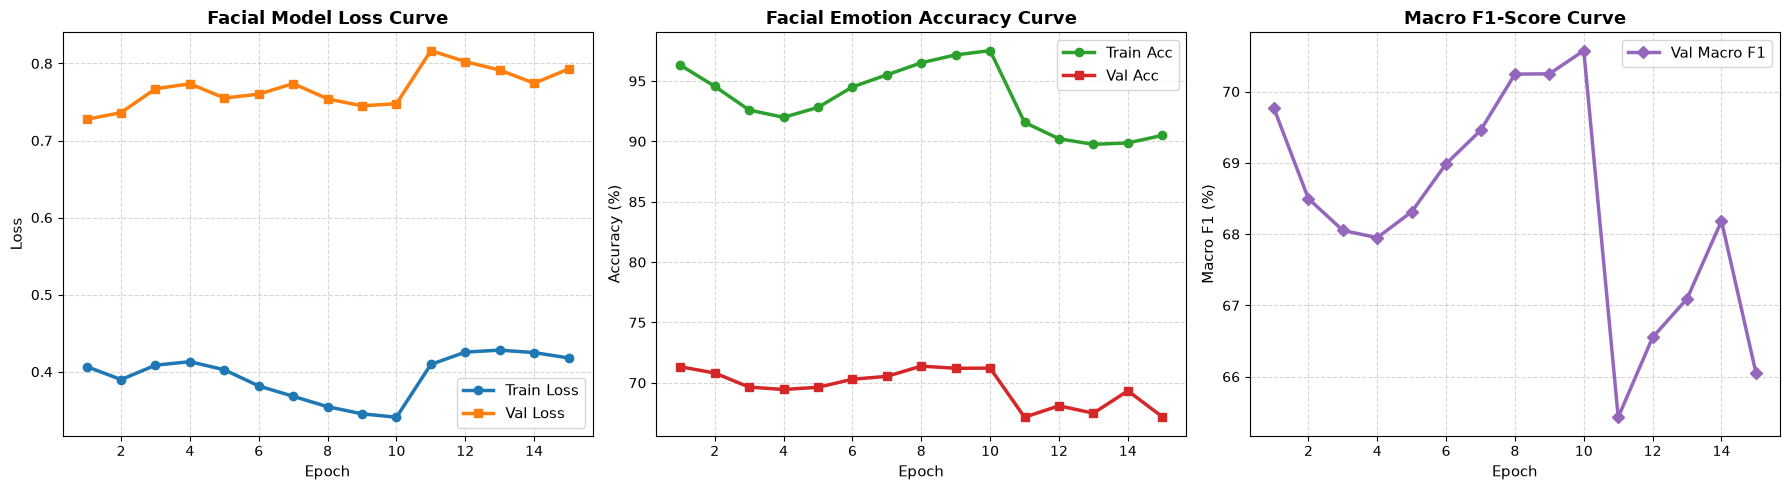

[SAVED] Percentage confusion matrix saved to: ./outputs\facial_confusion_matrix_percentage.png


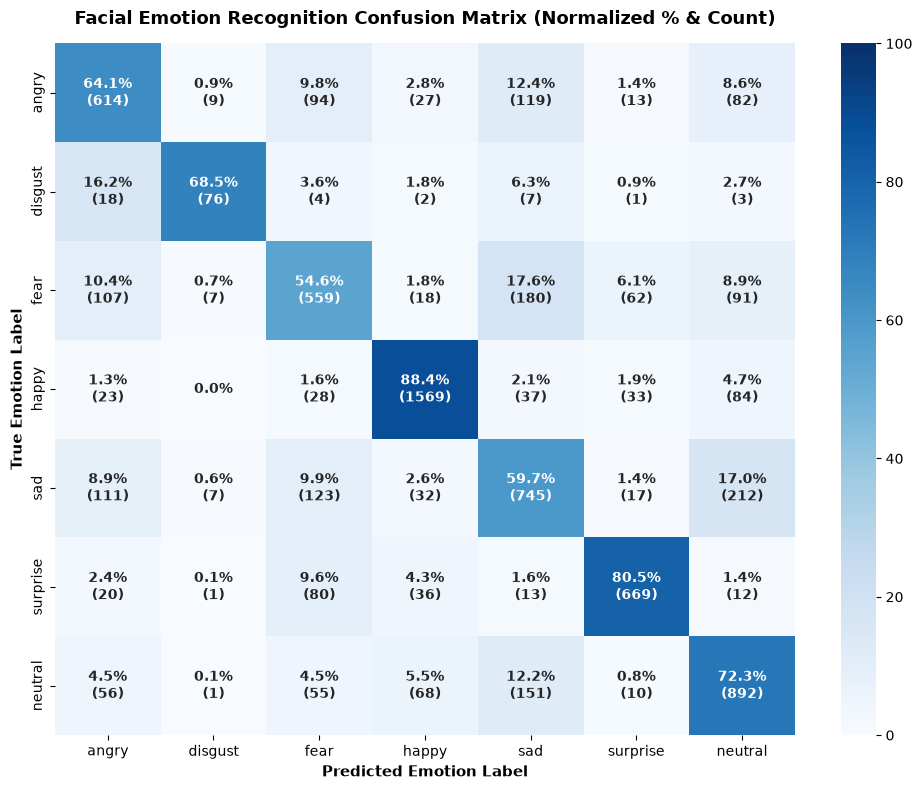


FACIAL EMOTION CLASSIFICATION REPORT (VAL / TEST SPLIT):
              precision    recall  f1-score   support

       angry     0.6470    0.6409    0.6439       958
     disgust     0.7525    0.6847    0.7170       111
        fear     0.5928    0.5459    0.5684      1024
       happy     0.8955    0.8844    0.8900      1774
         sad     0.5950    0.5974    0.5962      1247
    surprise     0.8311    0.8051    0.8178       831
     neutral     0.6483    0.7234    0.6838      1233

    accuracy                         0.7138      7178
   macro avg     0.7089    0.6974    0.7024      7178
weighted avg     0.7148    0.7138    0.7138      7178



In [7]:
# ==============================================================================
# CELL 7: EVALUATION VISUALIZATIONS & PERCENTAGE CONFUSION MATRICES
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

def plot_facial_training_curves(h: dict, output_dir: str = "./outputs"):
    """Plots training and validation loss, accuracy, and F1 curves across epochs."""
    epochs = h["epoch"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Loss Curve
    axes[0].plot(epochs, h["train_loss"], label="Train Loss", color="#1f77b4", lw=2.5, marker='o')
    axes[0].plot(epochs, h["val_loss"], label="Val Loss", color="#ff7f0e", lw=2.5, marker='s')
    axes[0].set_title("Facial Model Loss Curve", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Epoch", fontsize=11)
    axes[0].set_ylabel("Loss", fontsize=11)
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend(fontsize=11)

    # 2. Accuracy Curve
    axes[1].plot(epochs, h["train_acc"], label="Train Acc", color="#2ca02c", lw=2.5, marker='o')
    axes[1].plot(epochs, h["val_acc"], label="Val Acc", color="#d62728", lw=2.5, marker='s')
    axes[1].set_title("Facial Emotion Accuracy Curve", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Epoch", fontsize=11)
    axes[1].set_ylabel("Accuracy (%)", fontsize=11)
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend(fontsize=11)

    # 3. Macro F1 Curve
    axes[2].plot(epochs, h["val_f1"], label="Val Macro F1", color="#9467bd", lw=2.5, marker='D')
    axes[2].set_title("Macro F1-Score Curve", fontsize=13, fontweight='bold')
    axes[2].set_xlabel("Epoch", fontsize=11)
    axes[2].set_ylabel("Macro F1 (%)", fontsize=11)
    axes[2].grid(True, linestyle="--", alpha=0.5)
    axes[2].legend(fontsize=11)

    plt.tight_layout()
    os.makedirs(output_dir, exist_ok=True)
    out_file = os.path.join(output_dir, "facial_training_curves.png")
    plt.savefig(out_file, dpi=300, bbox_inches="tight")
    print(f"[SAVED] Training curves saved to: {out_file}")
    plt.show()


def plot_facial_confusion_matrix(eval_metrics: dict, class_names: dict, output_dir: str = "./outputs"):
    """Plots Confusion Matrix with explicit percentages (XX.X%) and sample counts in every cell."""
    labels = [class_names[i] for i in sorted(class_names.keys())]
    targets = eval_metrics["targets"]
    preds = eval_metrics["preds"]

    # Compute raw counts and normalized percentages
    cm_raw = confusion_matrix(targets, preds, labels=range(len(labels)))
    row_sums = cm_raw.sum(axis=1)[:, np.newaxis]
    cm_norm = np.divide(cm_raw.astype('float'), row_sums, out=np.zeros_like(cm_raw, dtype=float), where=row_sums!=0) * 100.0

    # Build custom annotation strings showing exact percentage and count
    annot_text = np.array([
        [f"{pct:.1f}%\n({int(cnt)})" if cnt > 0 else "0.0%"
         for pct, cnt in zip(r_pct, r_cnt)]
        for r_pct, r_cnt in zip(cm_norm, cm_raw)
    ])

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=annot_text, fmt="", cmap="Blues", cbar=True, vmin=0, vmax=100,
                xticklabels=labels, yticklabels=labels, ax=ax,
                annot_kws={"size": 10, "weight": "bold"})

    ax.set_title("Facial Emotion Recognition Confusion Matrix (Normalized % & Count)", fontsize=13, fontweight='bold', pad=14)
    ax.set_xlabel("Predicted Emotion Label", fontsize=11, fontweight='bold')
    ax.set_ylabel("True Emotion Label", fontsize=11, fontweight='bold')

    plt.tight_layout()
    os.makedirs(output_dir, exist_ok=True)
    out_file = os.path.join(output_dir, "facial_confusion_matrix_percentage.png")
    plt.savefig(out_file, dpi=300, bbox_inches="tight")
    print(f"[SAVED] Percentage confusion matrix saved to: {out_file}")
    plt.show()

    print("\n=======================================================")
    print("FACIAL EMOTION CLASSIFICATION REPORT (VAL / TEST SPLIT):")
    print("=======================================================")
    print(classification_report(targets, preds, target_names=labels, digits=4, zero_division=0))

# Execute Visualizations
plot_facial_training_curves(facial_history, output_dir=cfg["environment"]["output_dir"])
plot_facial_confusion_matrix(best_eval_results, class_names=cfg["taxonomy"]["class_names"], output_dir=cfg["environment"]["output_dir"])


In [9]:
# ==============================================================================
# CELL 8: MODEL SAVING & PRODUCTION .PT EXPORT PIPELINE
# ==============================================================================
def export_facial_models_as_pt(
    model: FacialEmotionModel,
    cfg: dict,
    history: Optional[dict] = None,
    eval_metrics: Optional[dict] = None,
    export_dir: str = "./checkpoints"
) -> Dict[str, str]:
    """
    Exports production-ready .pt models:
    1. Full checkpoint with weights, configs, taxonomy, and metrics ('best_facial_emotion_model.pt')
    2. Complete model object for direct torch.load() ('facial_emotion_model_complete.pt')
    3. Standalone individual backbones if ensemble is used
    """
    os.makedirs(export_dir, exist_ok=True)
    exported_files = {}

    # 1. Master Checkpoint (.pt)
    ckpt_pt_path = os.path.join(export_dir, "best_facial_emotion_model.pt")
    checkpoint_payload = {
        "model_state_dict": model.state_dict(),
        "config": cfg,
        "taxonomy": cfg["taxonomy"],
        "history": history,
        "evaluation_metrics": eval_metrics,
        "pytorch_version": torch.__version__
    }
    torch.save(checkpoint_payload, ckpt_pt_path)
    exported_files["checkpoint_pt"] = ckpt_pt_path
    print(f"[EXPORTED] Master Checkpoint (.pt): {ckpt_pt_path} ({os.path.getsize(ckpt_pt_path) / 1e6:.2f} MB)")

    # 2. Complete Model Object (.pt)
    complete_pt_path = os.path.join(export_dir, "facial_emotion_model_complete.pt")
    model_cpu = model.to("cpu")
    torch.save(model_cpu, complete_pt_path)
    model.to(device)  # restore original device
    exported_files["complete_model_pt"] = complete_pt_path
    print(f"[EXPORTED] Complete Model Object (.pt): {complete_pt_path} ({os.path.getsize(complete_pt_path) / 1e6:.2f} MB)")

    # 3. Individual Sub-Backbone Exports
    for name, submodel in model.models.items():
        sub_path = os.path.join(export_dir, f"facial_{name}_backbone.pt")
        torch.save(submodel.state_dict(), sub_path)
        exported_files[f"{name}_pt"] = sub_path
        print(f"[EXPORTED] Sub-Backbone ({name}) (.pt): {sub_path} ({os.path.getsize(sub_path) / 1e6:.2f} MB)")

    return exported_files

def verify_exported_facial_model(pt_path: str, cfg: dict, device: torch.device):
    """Verifies exported .pt file by loading and performing a test forward pass."""
    print(f"\n[VERIFICATION] Verifying model from: {pt_path} ...")
    payload = torch.load(pt_path, map_location=device, weights_only=False)

    test_model = FacialEmotionModel(cfg).to(device)
    if isinstance(payload, dict) and "model_state_dict" in payload:
        test_model.load_state_dict(payload["model_state_dict"])
    else:
        test_model = payload.to(device)
    test_model.eval()

    # Synthetic single-image test (1 image, 3 channels, 224x224 RGB)
    dummy_img = torch.randn(1, 3, cfg["preprocessing"]["image_size"], cfg["preprocessing"]["image_size"], device=device)

    with torch.no_grad():
        out = test_model(dummy_img)
        probs = F.softmax(out, dim=-1).cpu().numpy()[0]

    top_idx = int(np.argmax(probs))
    top_label = cfg["taxonomy"]["class_names"][top_idx]
    print(f"[VERIFIED] Test forward pass succeeded!")
    print(f"  • Predicted Emotion : '{top_label}' (Confidence: {probs[top_idx]*100:.2f}%)")
    print(f"  • Output Logits Shape: {out.shape} -> [Batch Size: 1, Num Classes: {cfg['taxonomy']['num_classes']}]")

# Execute Model Export & Verification
exported_paths = export_facial_models_as_pt(
    trained_facial_model,
    cfg,
    history=facial_history,
    eval_metrics=best_eval_results,
    export_dir=cfg["environment"]["checkpoint_dir"]
)
verify_exported_facial_model(exported_paths["checkpoint_pt"], cfg, device)


[EXPORTED] Master Checkpoint (.pt): ./checkpoints\best_facial_emotion_model.pt (469.93 MB)
[EXPORTED] Complete Model Object (.pt): ./checkpoints\facial_emotion_model_complete.pt (469.12 MB)
[EXPORTED] Sub-Backbone (efficientnet_b2) (.pt): ./checkpoints\facial_efficientnet_b2_backbone.pt (31.31 MB)
[EXPORTED] Sub-Backbone (resnet50) (.pt): ./checkpoints\facial_resnet50_backbone.pt (94.41 MB)
[EXPORTED] Sub-Backbone (vit_b_16) (.pt): ./checkpoints\facial_vit_b_16_backbone.pt (343.28 MB)

[VERIFICATION] Verifying model from: ./checkpoints\best_facial_emotion_model.pt ...
[INIT] Loaded custom weights: best_model efficient_b2.pt
[INIT] Loaded custom weights: best_model resnet50.pt
[INIT] Loaded custom weights: best_model vit b_16.pt
[VERIFIED] Test forward pass succeeded!
  • Predicted Emotion : 'neutral' (Confidence: 40.37%)
  • Output Logits Shape: torch.Size([1, 7]) -> [Batch Size: 1, Num Classes: 7]
